<a href="https://colab.research.google.com/github/YuncheKim/2026_discretemath/blob/main/1103discrete_dfsbfs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
graph_n = {
    '홍길동': ['김윤채', '하지민', '이지은', '조연주', '허남재'], #추가생성,아는 지인이 많은 인싸 홍길동


    '김윤채': ['김근영', '김성연', '조연주', '목은혜', '김다경'],
    '이지은': ['노다운', '이재은', '최시훈', '유채영', '한진주'],
    '최연희': ['하지민', '신지민', '백선우', '박은영', '허남재'],
    '양다영': ['김희진', '조수아', '김지은', '오수현', '고가은'],
    '박건우': ['이준서', '정우진', '최지훈', '전민성', '박지후']

}

이름 메모
김윤채| 김근영 김성연 조연주 목은혜 김다경

이지은| 노다운 이재은 최시훈 유채영 한진주

최연희| 하지민 신지민 백선우 박은영 허남재

양다영| 김희진 조수아 김지은 오수현 고가은

박건우| 이준서 정우진 최지훈 전민성 박지후

In [4]:
def dfs(graph_n, v, visited):
    visited.add(v)
    print(v, end=' ')
    for neighbor in graph_n.get(v, []):
        if neighbor not in visited:
            dfs(graph_n, neighbor, visited)

def DFS(graph_n):
    visited = set()
    for v in graph_n:
        if v not in visited:
            dfs(graph_n, v, visited)
    print()

def bfs(graph_n, v, visited):
    queue = [v]
    visited.add(v)
    while queue:
        u = queue.pop(0)
        print(u, end=' ')
        for neighbor in graph_n.get(u, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

def BFS(graph_n):
    visited = set()
    for v in graph_n:
        if v not in visited:
            bfs(graph_n, v, visited)
    print()

print("DFS탐색 순서:")
DFS(graph_n)
print("BFS탐색 순서:")
BFS(graph_n)

DFS탐색 순서:
홍길동 김윤채 김근영 김성연 조연주 목은혜 김다경 하지민 이지은 노다운 이재은 최시훈 유채영 한진주 허남재 최연희 신지민 백선우 박은영 양다영 김희진 조수아 김지은 오수현 고가은 박건우 이준서 정우진 최지훈 전민성 박지후 
BFS탐색 순서:
홍길동 김윤채 하지민 이지은 조연주 허남재 김근영 김성연 목은혜 김다경 노다운 이재은 최시훈 유채영 한진주 최연희 신지민 백선우 박은영 양다영 김희진 조수아 김지은 오수현 고가은 박건우 이준서 정우진 최지훈 전민성 박지후 


In [5]:
print("DFS탐색 순서:")
dfs(graph_n, '홍길동', set())


DFS탐색 순서:
홍길동 김윤채 김근영 김성연 조연주 목은혜 김다경 하지민 이지은 노다운 이재은 최시훈 유채영 한진주 허남재 

In [6]:
print("BFS탐색 순서:")
bfs(graph_n, '홍길동', set())

BFS탐색 순서:
홍길동 김윤채 하지민 이지은 조연주 허남재 김근영 김성연 목은혜 김다경 노다운 이재은 최시훈 유채영 한진주 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 109.5 MB/s  0:00:00


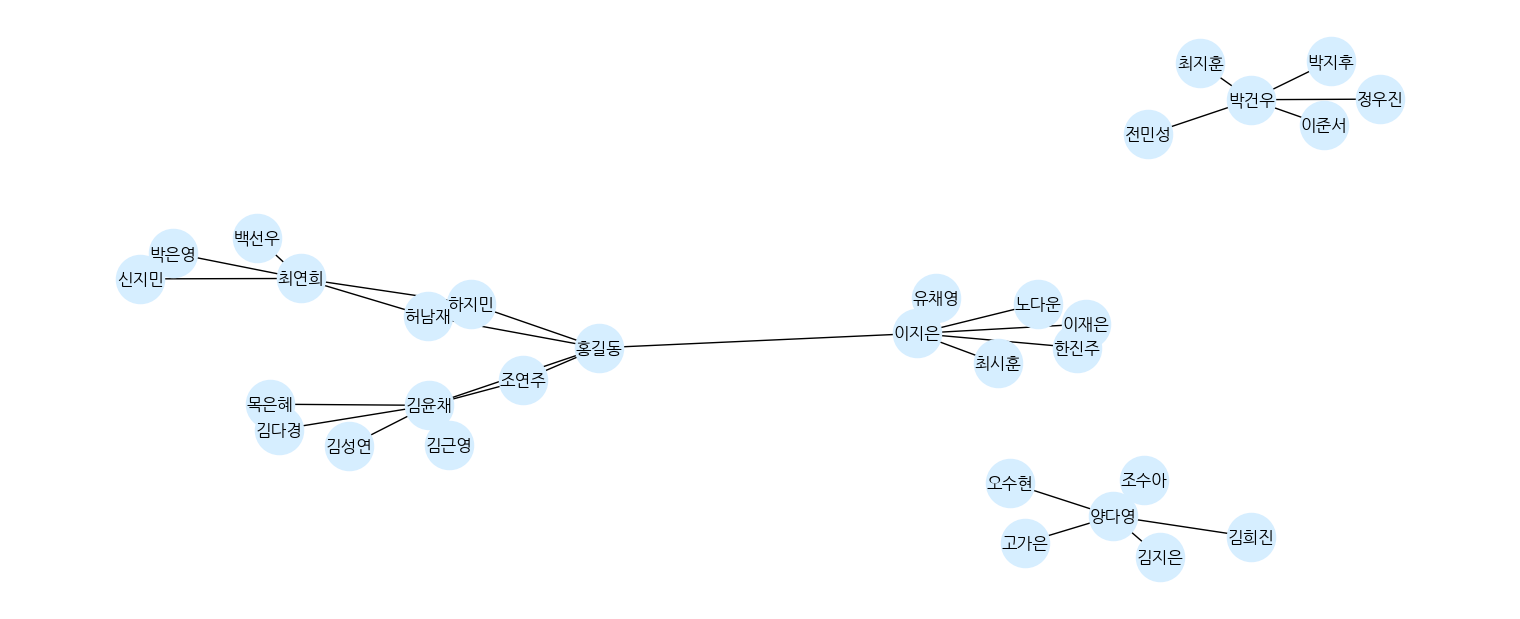

In [7]:
#시각화import
!pip install koreanize-matplotlib
import networkx as nx
import matplotlib.pyplot as plt
import koreanize_matplotlib

G = nx.Graph(graph_n)
plt.figure(figsize=(15, 6))
nx.draw(G, with_labels=True, node_color='#D6EEFF', node_size=1200,font_family='NanumGothic')
plt.show()


In [17]:
from collections import deque

def gamyeom(graph, start):
  visited = set()
  queue = deque([(start, 0)])

  print(f"{start}의 2단계 접촉자!")

  while queue:
    current, depth = queue.popleft()
    if current not in visited:
      visited.add(current)
      if 1<= depth <= 2:
        print("-", current, f"({depth}단계)")
      if depth < 2:
        for neighbor in graph[current]:
          queue.append((neighbor, depth + 1))

In [22]:
import random

def make_graph(n, depth, seed):                 # depth: P0에서 가장 먼 거리
  random.seed(seed)                             # 같은 seed면 항상 같은 그래프가 나오게
  names = [f"P{i}" for i in range(n)]           # 노드 이름 목록들
  graph = {name: [] for name in names}          # 모든 노드를 키로 빈 리스트를 value로 하는 인접 리스트 딕셔너리

  others = names[1:]                            # 시작점 P0를 뺀 나머지 노드들
  random.shuffle(others)                        # random 모듈로 순서를 섞어서 번호와 단계가 무작위
  levels = [["P0"]] + [[] for _ in range(depth)]  # 단계별 노드들
  for i, name in enumerate(others):             # enumerate로 순번과 값을 동시에 꺼냄
    if i < depth:
      lv = i + 1                                # 앞에서부터 depth명까지는 1단계, 2단계 이렇게 순서대로 한 명씩
    else:
      lv = random.randint(1, depth)             # 나머지는 1~depth 중 아무 단계나 랜덤으로
    levels[lv].append(name)

  def add_edge(u, v):
    if u != v and v not in graph[u]:            # 자기 자신 연결 금지 이미 연결돼 있으면 중복 금지
      graph[u].append(v)                        # u의 접촉자 목록에 v 추가
      graph[v].append(u)                        # v의 접촉자 목록에도 u 추가

  for lv in range(1, depth + 1):
    for name in levels[lv]:                     # 1단계부터 depth단계까지 차례로 모든 노드에 대해
      add_edge(name, random.choice(levels[lv - 1]))  # 바로 윗단계 노드 하나와 랜덤으로 연결

  return graph

graph_n = make_graph(1000, 50, 42)
gamyeom(graph_n, "P0")

P0의 2단계 접촉자!
- P873 (1단계)
- P158 (1단계)
- P919 (1단계)
- P6 (1단계)
- P751 (1단계)
- P862 (1단계)
- P325 (1단계)
- P23 (1단계)
- P209 (1단계)
- P107 (1단계)
- P254 (1단계)
- P908 (1단계)
- P699 (1단계)
- P29 (2단계)
- P157 (2단계)
- P385 (2단계)
- P972 (2단계)
- P731 (2단계)
- P924 (2단계)
- P268 (2단계)
- P647 (2단계)
- P790 (2단계)
- P765 (2단계)
- P602 (2단계)
- P981 (2단계)
- P777 (2단계)
- P310 (2단계)
- P507 (2단계)
- P941 (2단계)


**사용 AI** : Claude-Opus 5.5

**prompt 내용** :


첨부한2단계 전염 경로 추적 gamyeom함수를 BFS로 만든 것임
이 함수를 테스트하려는데 노드1000개짜리 그래프는 손으로 못 만들어서 테스트용 그래프 생성 함수 make_graph(n, depth, seed)를 파이썬으로 만들어줘
조건은 다 지켜서 생성해
우선 random모듈을 임포트해서 써줘
인접 리스트 딕셔너리로 반환하고
노드 이름은 'P0'다음'P1'이렇게하고 근데 시작점은 'P0'
P0에서 가장 먼 노드까지 거리는 depth가 되게 하고
모든 노드가 P0이랑 연결된 무방향 그래프 중복 간선이나 자기 자신 연결은 하지마
씨드가 같으면 같은 그래프가 나오게 하고


**[def gamyeom 함수의 내용을 추가로 첨부]**